# PSA_Event: 吸収点と 1 ヒットの判定(Reconstruct へ渡す)

`PSA_Calibration` までは、ヒットを「ボード ha04 の ch2 のピクセル (n = 5, m = 3)、エネルギー E」という**検出器の中の番号**で持っています。
コンプトンの再構成(`Reconstruct`)には、**検出器座標での吸収点 $P_g$ [mm] と散乱ガンマ線のエネルギー $E_g$** が要ります。
`PSA_Event` はその間をつなぐモジュールで、SMILE-2+ の `HA_Calc` の後半(ピクセル → 吸収点、シングルヒットの判定)に当たります。

| 手順 | 中身 |
|---|---|
| 1. 使えるヒット | ピクセルがあり(`pixel >= 0`)、`energy > energy_min` で、そのブロック(board, ch)が `geometry_file` にあるヒット |
| 2. 吸収点 | $P_g = (x_0, y_0, z_0) + \mathrm{pitch}\,[(n - 4.5)\,\mathbf u + (m - 4.5)\,\mathbf v]$ [mm] |
| 3. ヒットの数 | 使えるヒットが 1 つ: `PSA_SingleHit`、2 つ以上: `PSA_MultiHit`、0: `PSA_NoHits`(イベント選択のフラグ。イベントは飛ばさない) |

`Reconstruct` は、`PSA_SingleHit` のイベントで $E_g$, $P_g$ を受け取り、`Reconstruct/single_hit` に書きます
(SMILE-2+ のデータでは `HA_Calc_2p` → `Reconstruct_2p`)。

### ジオメトリのファイル `calib/psa/geometry.csv`

1 行に 1 ブロックです(単位 mm、座標は [0_Introduction](../../../0_Introduction/Introduction.ipynb) のもの: 原点は μ-PIC の中央、X は W → E、Y は N → S、Z は下向き)。

```
board,ch,x0,y0,z0,ux,uy,uz,vx,vy,vz,pitch
```

| 列 | 中身 |
|---|---|
| `x0, y0, z0` | 8 × 8 のブロックの中心 |
| `ux, uy, uz` | ピクセル番号 n が増える向きの単位ベクトル |
| `vx, vy, vz` | m が増える向きの単位ベクトル |
| `pitch` | ピクセルの間隔 |

> **今の状態**: ブロックの位置と向き、ピクセルの間隔の値がまだ決まっていないので、`geometry.csv` はありません(形だけの `geometry_template.csv` がある)。
> そのため今はどのヒットも使われず、`single_hit` は空です。下の 4 節は、**仕組みを見るためだけの例の値**で流しています。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有、git には入れない)
CACHE.mkdir(exist_ok=True)

def th2(h):
    """ROOT の TH2 -> (中身 [x のビン, y のビン], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    a = np.frombuffer(h.GetArray(), dtype=np.float64, count=(nx + 2) * (ny + 2)).reshape(ny + 2, nx + 2)
    ex = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ey = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return a[1:-1, 1:-1].T.copy(), ex, ey

def show_params(config, module):
    """設定ファイルの、あるモジュールのパラメータを、説明(_doc)と単位(_units)つきで表示する"""
    p = json.load(open(REPO / "config" / f"{config}.json"))["parameters"][module]
    doc, units = p.get("_doc", {}), p.get("_units", {})
    for k, v in p.items():
        if k.startswith("_"):
            continue
        u = f" [{units[k]}]" if k in units else ""
        print(f"{k} = {json.dumps(v, ensure_ascii=False)}{u}\n    {doc.get(k, '')}")

## 1. データの準備

TPC と PSA を一緒に読むので、ETCC のラン **`20261102_run04`**(211 イベント)を使います。
`ReadData`(TPC)は 1 つのディレクトリしか読めないので、2 つの storage のファイルへのシンボリックリンクを `tutorials/cache/` の中に集めます。

In [2]:
DATA = Path(os.environ.get("SMILE3_FM_DATA", "/mnt/nas_eureka/SMILE-3FM_data"))
RUN = "20261102_run04"
SRC = [DATA / "20261102" / "calltt" / RUN, DATA / "20261102" / "killua" / RUN]
for d in SRC:
    print("OK     " if d.is_dir() else "MISSING", d)
RUN_DIR = CACHE / f"etcc_{RUN}"   # 両方の storage のファイルへのリンクを集めたディレクトリ
RUN_DIR.mkdir(exist_ok=True)
for d in SRC:
    for p in list(d.glob("ha*_*.dat")) + list(d.glob("tpc_enc_*.raw")):
        if not (RUN_DIR / p.name).exists():
            (RUN_DIR / p.name).symlink_to(p)
print(len(list(RUN_DIR.iterdir())), "files in", RUN_DIR)

OK      /mnt/nas_eureka/SMILE-3FM_data/20261102/calltt/20261102_run04
OK      /mnt/nas_eureka/SMILE-3FM_data/20261102/killua/20261102_run04
37 files in /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/etcc_20261102_run04


## 2. 今の較正ファイルで流す

設定ファイル `smile3_reconstruct_psa`(`ReadData → PSA_* → CalcFADC → TPC_Calibration → PSA_Event → Reconstruct`)で流します。
`geometry.csv` が無いという警告が出て、`PSA_Event/NHits`(1 イベントの使えるヒットの数)は全部 0 になります。

In [3]:
def run_chain(out, *args):
    cmd = [sys.executable, str(RUN_CHAIN), "smile3_reconstruct_psa", "-o", str(out), "--data-dir", str(RUN_DIR), *args]
    print(" ".join(cmd))
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()
    return r

OUT_NOW = CACHE / f"reconstruct_psa_{RUN}.root"
r = run_chain(OUT_NOW)
print("\n".join(l for l in (r.stdout + r.stderr).splitlines() if l.startswith("PSA_Event")))
f = ROOT.TFile(str(OUT_NOW))
h = f.Get("PSA_Event/NHits")
print("NHits:", {int(h.GetBinCenter(i)): int(h.GetBinContent(i)) for i in range(1, h.GetNbinsX() + 1) if h.GetBinContent(i)})
print("single_hit entries:", f.Get("Reconstruct/single_hit").GetEntries())

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_reconstruct_psa -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/reconstruct_psa_20261102_run04.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/etcc_20261102_run04


PSA_Event: 448 hits with energy were not used (block not in geometry_file)
PSA_Event: WARNING: no geometry_file /home/onoda/ANLNext/Erica_git_dev/EricaNext/calib/psa/geometry.csv; no hit has a position
NHits: {0: 211}
single_hit entries: 0


## 3. どこで止まっているか

`PSA_TreeWriter/psa` を見ると、ピクセルとエネルギーは決まっていますが、`geometry.csv` が無いので手順 1 でどのヒットも落ちています。

In [4]:
d = ROOT.RDataFrame("PSA_TreeWriter/psa", str(OUT_NOW)).AsNumpy(["pixel", "energy"])
print("hits:", len(d["pixel"]), " with pixel:", int((d["pixel"].astype(int) >= 0).sum()), " with energy > 0:", int((d["energy"] > 0).sum()))

hits: 555  with pixel: 451  with energy > 0: 448


## 4. 例の値で仕組みを見る

**ここで使う値は、仕組みを見るためだけの作り物です(実際の配置・較正ではありません)。** `tutorials/cache/example_psa_cal/` に書き、
`--set` でそのときだけ使います。

- ジオメトリ: ボード b の ch c のブロックの中心を (100 b, 50 c, 200) mm、u = X 方向、v = Y 方向、pitch 6 mm
- エネルギー: 全ピクセルで `energy = 0.01 × hg_corr`(`calib/psa` のエネルギーの較正の代わりに、例の値を使う。温度ゲインは `calib/psa` のもの)

吸収点が手順 2 の式どおりになっていること、1 ヒットのイベントだけが `single_hit` に入ることを確かめます。

In [5]:
EX = CACHE / "example_psa_cal"
EX.mkdir(exist_ok=True)
boards = sorted({int(p.name[2:4]) for p in RUN_DIR.glob("ha*_*.dat")})
with open(EX / "geometry.csv", "w") as g:
    g.write("# EXAMPLE values for the tutorial, not the real geometry\nboard,ch,x0,y0,z0,ux,uy,uz,vx,vy,vz,pitch\n")
    for b in boards:
        for c in range(6):
            g.write(f"{b},{c},{100 * b},{50 * c},200,1,0,0,0,1,0,6\n")
for b in boards:
    with open(EX / f"energy_ha{b:02d}.csv", "w") as e:
        e.write("ch,n,m,p0,p1\n" + "".join(f"{c},{n},{m},0,0.01\n" for c in range(6) for n in range(1, 9) for m in range(1, 9)))

OUT_EX = CACHE / f"reconstruct_psa_{RUN}_example.root"
r = run_chain(OUT_EX, "--set", f"PSA_Calibration.energy_dir={EX}", "--set", f"PSA_Event.geometry_file={EX / 'geometry.csv'}")
f = ROOT.TFile(str(OUT_EX))
h = f.Get("PSA_Event/NHits")
print("NHits:", {int(h.GetBinCenter(i)): int(h.GetBinContent(i)) for i in range(1, h.GetNbinsX() + 1) if h.GetBinContent(i)})
for l in r.stdout.splitlines():
    if l.startswith(("PSA_SingleHit", "PSA_MultiHit", "PSA_NoHits", "NotConformEnergy")):
        print(l)

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_reconstruct_psa -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/reconstruct_psa_20261102_run04_example.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/etcc_20261102_run04 --set PSA_Calibration.energy_dir=/home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/example_psa_cal --set PSA_Event.geometry_file=/home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/example_psa_cal/geometry.csv


NHits: {0: 10, 1: 62, 2: 62, 3: 53, 4: 17, 5: 7}
NotConformEnergy                                           26                0
PSA_MultiHit                                              139              139
PSA_NoHits                                                 10               10
PSA_SingleHit                                              62               36


`PSA_SingleHit` のイベントのうち、`Reconstruct` で運動学が合わないもの(`NotConformEnergy`)を除いたものが `single_hit` に入ります。
`single_hit` の `evt_id`(トリガーカウンタ)で `PSA_TreeWriter/psa` の行と結び付け、$E_g$ と $P_g$ が式どおりかを確かめます。

33 rows in single_hit, rows that differ from the formula: 0


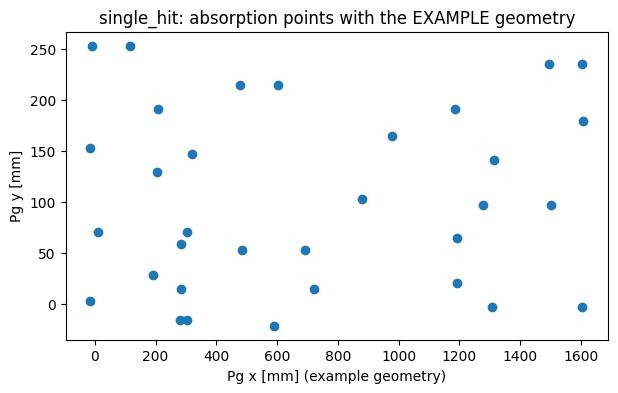

In [6]:
p = ROOT.RDataFrame("PSA_TreeWriter/psa", str(OUT_EX)).AsNumpy(["trig", "board", "ch", "pix_n", "pix_m", "pixel", "hg_corr", "energy"])
for k in ["board", "ch", "pix_n", "pix_m", "pixel"]:
    p[k] = p[k].astype(int)
s = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT_EX)).AsNumpy(["evt_id", "Eg", "Ke", "Pg"])
used = (p["pixel"] >= 0) & (p["energy"] > 0)
n_bad = 0
for t_, eg, pg in zip(s["evt_id"], s["Eg"], s["Pg"]):
    k = np.where(used & (p["trig"] == t_))[0]
    assert len(k) == 1          # single_hit のイベントには、使えるヒットがちょうど 1 つ
    k = k[0]
    expect = np.array([100 * p["board"][k], 50 * p["ch"][k], 200]) + 6 * np.array([p["pix_n"][k] - 4.5, p["pix_m"][k] - 4.5, 0])
    n_bad += abs(eg - 0.01 * p["hg_corr"][k]) > 1e-9 or np.abs(np.asarray(pg) - expect).max() > 1e-9
print(len(s["evt_id"]), "rows in single_hit, rows that differ from the formula:", n_bad)
pg = np.stack([np.asarray(v) for v in s["Pg"]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pg[:, 0], pg[:, 1], "o")
ax.set_xlabel("Pg x [mm] (example geometry)"); ax.set_ylabel("Pg y [mm]"); ax.set_title("single_hit: absorption points with the EXAMPLE geometry")
plt.show()

## 5. パラメータ

`config/smile3_reconstruct_psa.json` の `PSA_Event` のパラメータです。

In [7]:
show_params("smile3_reconstruct_psa", "PSA_Event")

geometry_file = "{repo}/calib/psa/geometry.csv"
    ブロック(board, ch)ごとの位置と向き(board,ch,x0,y0,z0,ux,uy,uz,vx,vy,vz,pitch)。ピクセル (n, m) の吸収点 = (x0,y0,z0) + pitch((n-4.5)u + (m-4.5)v) [mm]。書き方は config/README.md
energy_min = 0.0 [keV]
    このエネルギーより大きいヒットだけ使う(ピクセルとエネルギーがあり、geometry_file にあるブロックのヒット)
save_hists = true
    true: 使ったヒットの数(NHits)と 1 ヒットのイベントのエネルギー(SingleHitEnergy)を保存する
